<a href="https://colab.research.google.com/github/diloo11/PCVK_Ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# akses drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


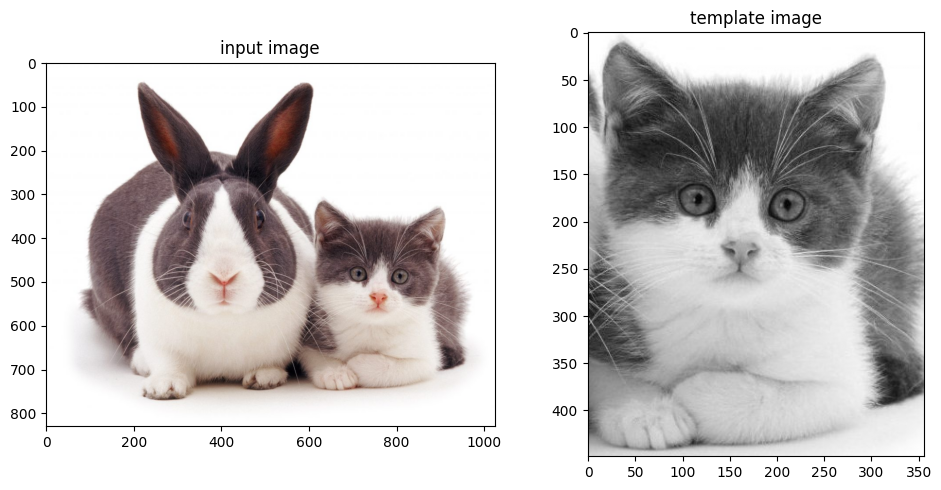

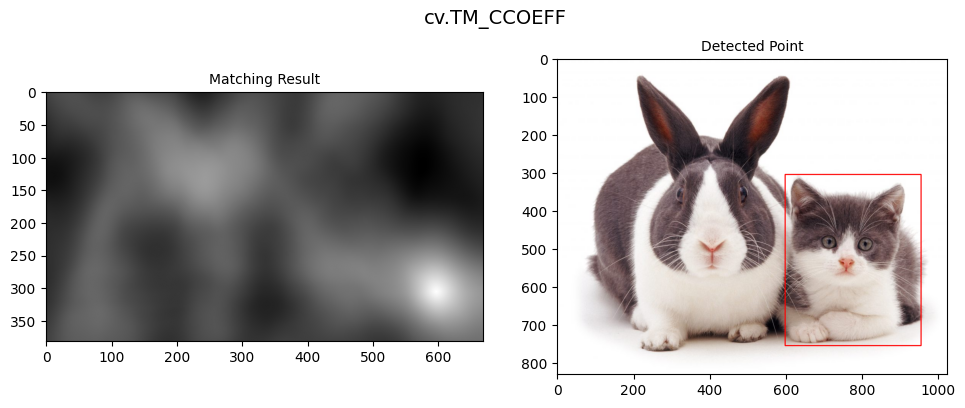

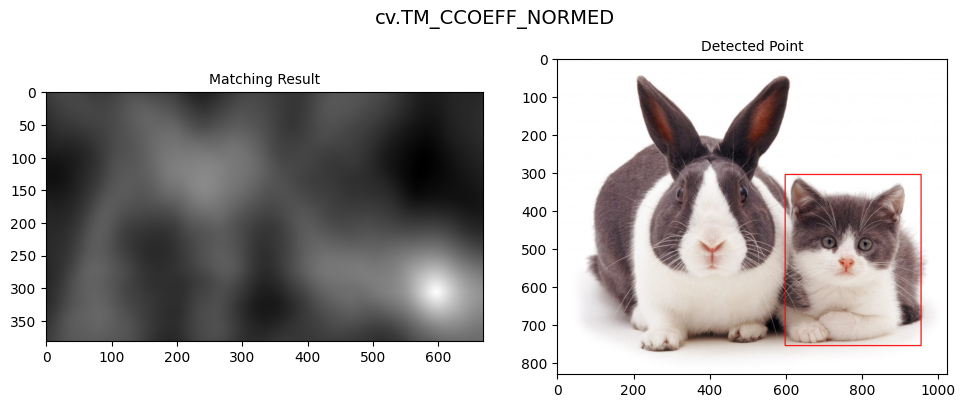

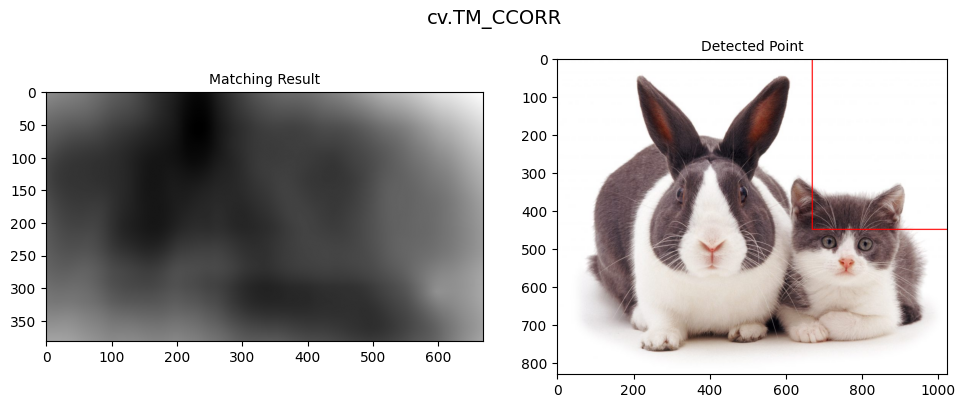

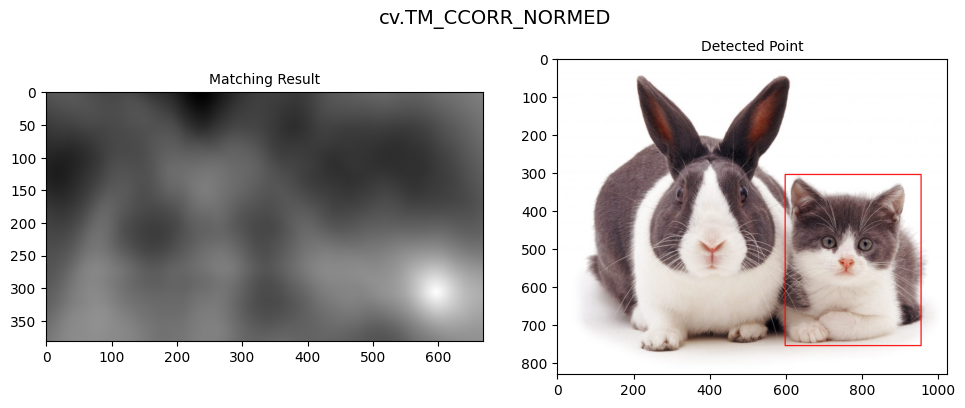

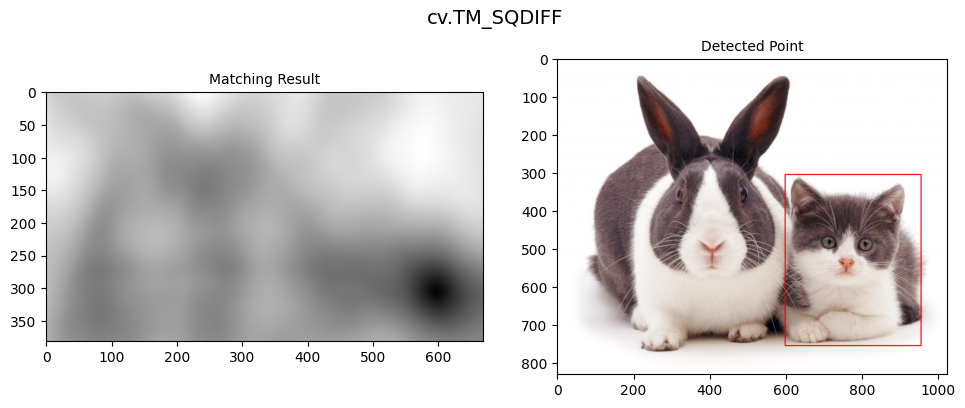

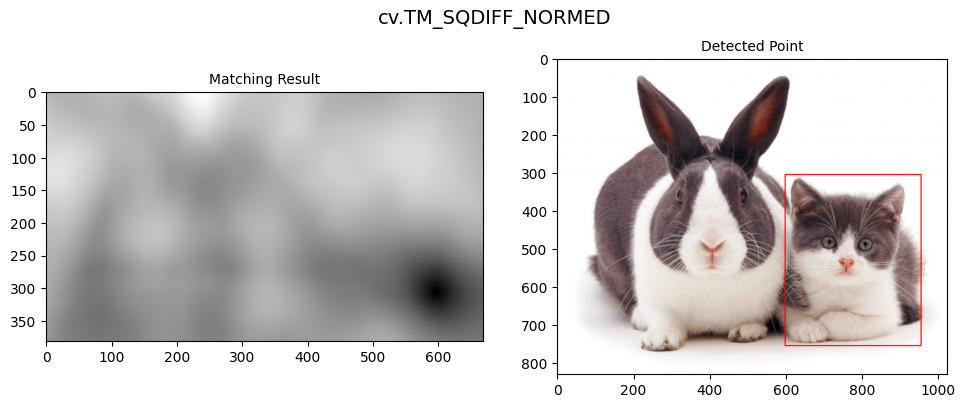

In [3]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar input dan citra template
img = cv.imread('/content/drive/MyDrive/PCVK/Images/cats_and_bunnies.jpg')
assert (
    img is not None
), 'File input gambar tidak ditemukan. Periksa path direktori Anda.'

# Ubah ke RGB untuk visualisasi menggunakan matplotlib
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

template = cv.imread('/content/drive/MyDrive/PCVK/Images/cat2_templatejpg.jpg', 0)  # Baca langsung sebagai grayscale
assert (
    template is not None
), 'File template gambar tidak ditemukan. Periksa path direktori Anda.'

w, h = template.shape[::-1]

# 2. Daftar 6 metode template matching di OpenCV
methods = [
    'cv.TM_CCOEFF',
    'cv.TM_CCOEFF_NORMED',
    'cv.TM_CCORR',
    'cv.TM_CCORR_NORMED',
    'cv.TM_SQDIFF',
    'cv.TM_SQDIFF_NORMED',
]

# Tampilkan citra input dan template terlebih dahulu
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('input image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('template image')
plt.axis('on')
plt.tight_layout()
plt.show()

# 3. Looping untuk setiap metode template matching
for meth in methods:
  img_copy = img_rgb.copy()
  method = eval(meth)

  # Lakukan template matching
  res = cv.matchTemplate(img_gray, template, method)
  min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

  # Untuk metode SQDIFF dan SQDIFF_NORMED, kecocokan minimum bernilai terbaik
  if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
    top_left = min_loc
  else:
    top_left = max_loc

  bottom_right = (top_left[0] + w, top_left[1] + h)

  # Gambar kotak merah pada objek yang terdeteksi
  cv.rectangle(img_copy, top_left, bottom_right, (255, 0, 0), 2)

  # Plot hasil matching result dan detected point
  plt.figure(figsize=(10, 4))
  plt.suptitle(meth, fontsize=14)

  plt.subplot(1, 2, 1)
  plt.imshow(res, cmap='gray')
  plt.title('Matching Result', fontsize=10)
  plt.axis('on')

  plt.subplot(1, 2, 2)
  plt.imshow(img_copy)
  plt.title('Detected Point', fontsize=10)
  plt.axis('on')

  plt.tight_layout()
  plt.show()

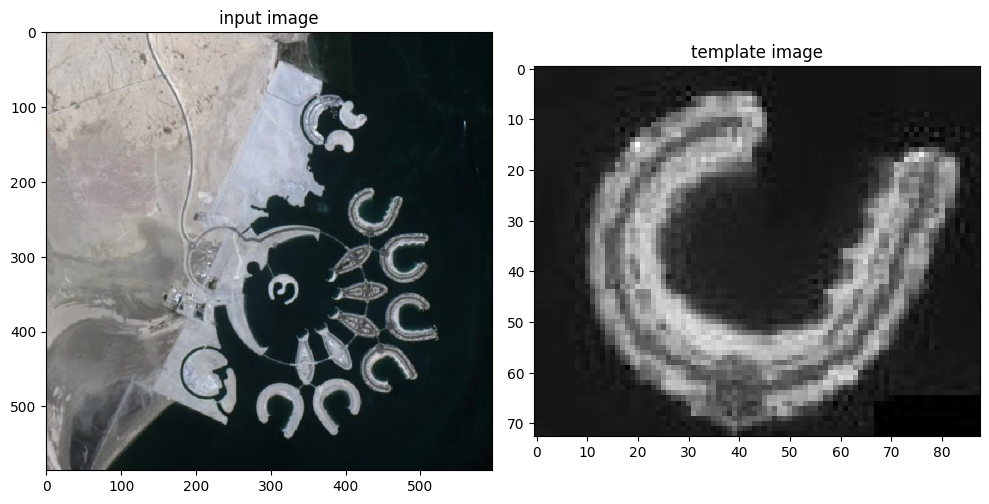

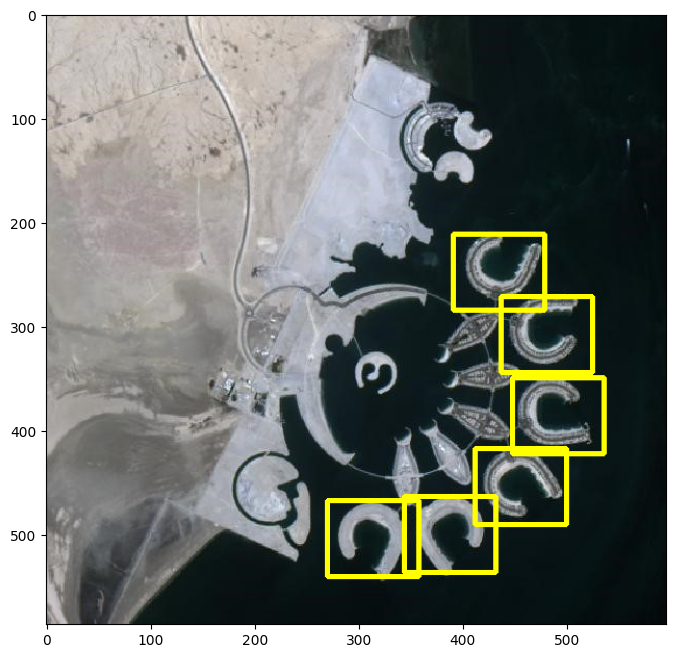

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar input dan citra template
img = cv.imread('/content/drive/MyDrive/PCVK/Images/bahrain.jpg')
assert img is not None, 'File bahrain.jpg tidak ditemukan.'
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY).astype(np.float32)

template = cv.imread(
    '/content/drive/MyDrive/PCVK/Images/bahrain-template.jpg', 0
).astype(np.float32)

h_temp, w_temp = template.shape

# Tampilkan citra input dan template awal
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('input image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('template image')
plt.axis('on')
plt.tight_layout()
plt.show()

# 2. Implementasi Template Matching Manual (Normalized Cross-Correlation) tanpa cv.matchTemplate
template_mean = template - np.mean(template)
template_std = np.std(template)

h_img, w_img = img_gray.shape
result = np.zeros((h_img - h_temp + 1, w_img - w_temp + 1))

for y in range(result.shape[0]):
  for x in range(result.shape[1]):
    patch = img_gray[y : y + h_temp, x : x + w_temp]
    patch_mean = patch - np.mean(patch)
    patch_std = np.std(patch)

    if patch_std == 0 or template_std == 0:
      result[y, x] = 0
    else:
      result[y, x] = np.sum(patch_mean * template_mean) / (
          patch_std * template_std * template.size
      )

# 3. Thresholding dan Non-Maximum Suppression (NMS) untuk Multiple Object
threshold = 0.45
loc = np.where(result >= threshold)

rectangles = []
for pt in zip(*loc[::-1]):
  rectangles.append((pt[0], pt[1], w_temp, h_temp))


def non_max_suppression(rects, overlapThresh=0.2):
  if len(rects) == 0:
    return []
  boxes = np.array(rects, dtype=float)
  pick = []
  x1 = boxes[:, 0]
  y1 = boxes[:, 1]
  x2 = boxes[:, 0] + boxes[:, 2]
  y2 = boxes[:, 1] + boxes[:, 3]
  area = (x2 - x1 + 1) * (y2 - y1 + 1)
  idxs = np.argsort(y2)

  while len(idxs) > 0:
    last = len(idxs) - 1
    i = idxs[last]
    pick.append(i)
    xx1 = np.maximum(x1[i], x1[idxs[:last]])
    yy1 = np.maximum(y1[i], y1[idxs[:last]])
    xx2 = np.minimum(x2[i], x2[idxs[:last]])
    yy2 = np.minimum(y2[i], y2[idxs[:last]])
    w = np.maximum(0, xx2 - xx1 + 1)
    h = np.maximum(0, yy2 - yy1 + 1)
    overlap = (w * h) / area[idxs[:last]]
    idxs = np.delete(
        idxs, np.concatenate(([last], np.where(overlap > overlapThresh)[0]))
    )
  return boxes[pick].astype(int)


boxes = non_max_suppression(rectangles, overlapThresh=0.2)

# Gambar kotak kuning pada objek yang terdeteksi
img_detected = img_rgb.copy()
for x, y, w, h in boxes:
  cv.rectangle(img_detected, (x, y), (x + w, y + h), (255, 255, 0), 3)

# Tampilkan hasil akhir deteksi multiple object
plt.figure(figsize=(8, 8))
plt.imshow(img_detected)
plt.axis('on')
plt.show()

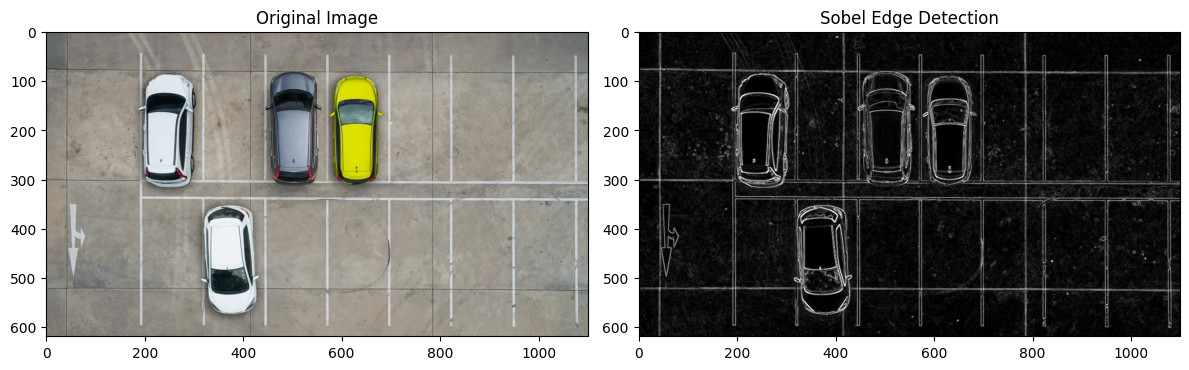

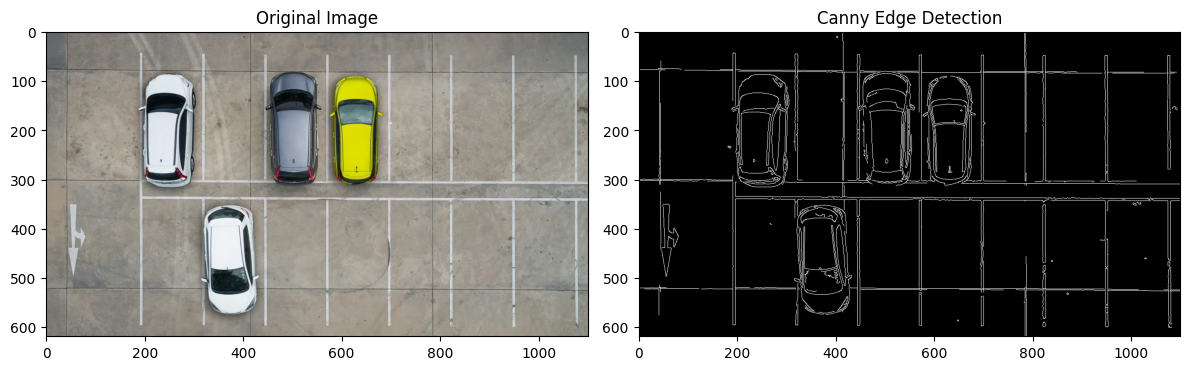

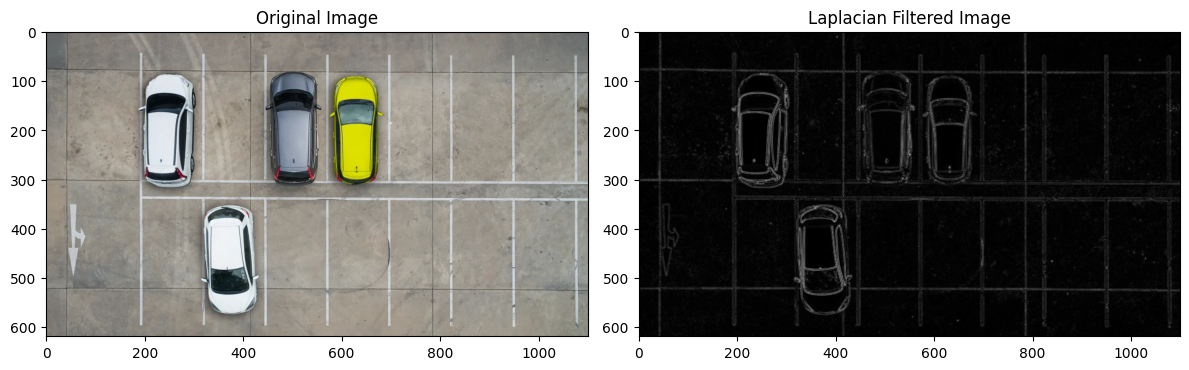

In [5]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar input (pastikan path direktori Google Drive Anda sudah sesuai)
img = cv.imread('/content/drive/MyDrive/PCVK/Images/car-park.jpg')

# Ubah ke Grayscale karena deteksi tepi memerlukan citra keabuan
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# ==========================================
# A. SOBEL EDGE DETECTION
# ==========================================
# Menghitung gradien arah X dan Y dengan kernel ukuran 3x3
sobelx = cv.Sobel(img_gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(img_gray, cv.CV_64F, 0, 1, ksize=3)

# Mengubah kembali ke tipe uint8 agar bisa ditampilkan dengan benar
abs_sobelx = cv.convertScaleAbs(sobelx)
abs_sobely = cv.convertScaleAbs(sobely)
sobel_combined = cv.addWeighted(abs_sobelx, 0.5, abs_sobely, 0.5, 0)

# Visualisasi Sobel Edge Detection
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(sobel_combined, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('on')
plt.tight_layout()
plt.show()

# ==========================================
# B. CANNY EDGE DETECTION
# ==========================================
# Tahap Canny: Gaussian Blur terlebih dahulu untuk mengurangi noise, lalu Canny
blurred = cv.GaussianBlur(img_gray, (3, 3), 0)
canny_edges = cv.Canny(blurred, 100, 200)  # Threshold bawah dan atas

# Visualisasi Canny Edge Detection
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('on')
plt.tight_layout()
plt.show()

# ==========================================
# C. LAPLACIAN EDGE DETECTION
# ==========================================
# Menghaluskan gambar dengan Gaussian filter terlebih dahulu karena Laplacian sangat sensitif terhadap noise
blur_laplacian = cv.GaussianBlur(img_gray, (3, 3), 0)
laplacian = cv.Laplacian(blur_laplacian, cv.CV_64F)
laplacian_result = cv.convertScaleAbs(laplacian)

# Visualisasi Laplacian Edge Detection
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(laplacian_result, cmap='gray')
plt.title('Laplacian Filtered Image')
plt.axis('on')
plt.tight_layout()
plt.show()

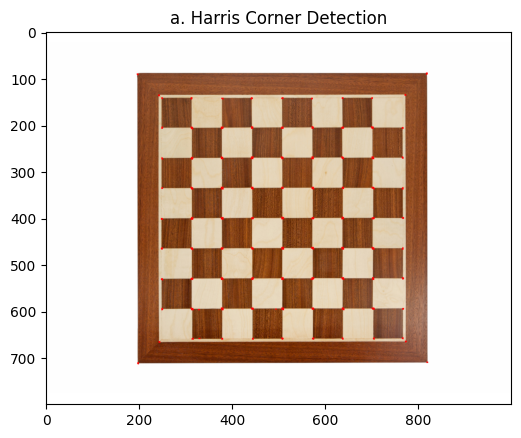

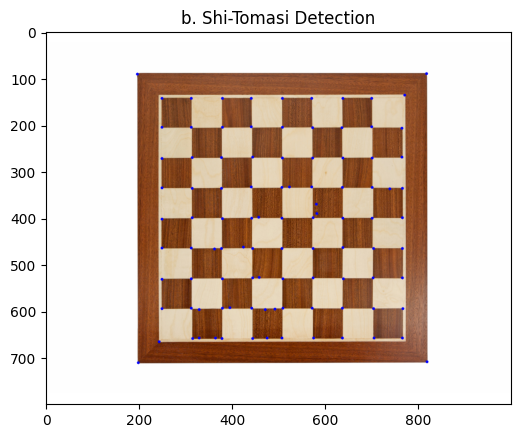

In [7]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar input
img = cv.imread('/content/drive/MyDrive/PCVK/Images/chess-board.jpg')
# Konversi ke Grayscale dan RGB
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray = np.float32(gray)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# ==========================================
# A. HARRIS CORNER DETECTION
# ==========================================
# Parameter cornerHarris: src, blockSize, ksize, k
dst = cv.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)

# Dilasi untuk memperbesar titik sudut agar mudah ditandai
dst = cv.dilate(dst, None)

# Threshold untuk menandai sudut (nilai threshold disesuaikan dengan gambar)
img_harris = img_rgb.copy()
img_harris[dst > 0.01 * dst.max()] = [255, 0, 0]  # Tandai dengan warna merah

# Visualisasi Harris Corner Detection
plt.figure(figsize=(6, 6))
plt.imshow(img_harris)
plt.title('a. Harris Corner Detection')
plt.axis('on')
plt.show()

# ==========================================
# B. SHI-TOMASI CORNER DETECTION
# ==========================================
# Menggunakan fungsi goodFeaturesToTrack() untuk mendeteksi N sudut terkuat
# Parameter: image, maxCorners, qualityLevel, minDistance
corners = cv.goodFeaturesToTrack(gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int64(corners)

img_shitomasi = img_rgb.copy()
for i in corners:
  x, y = i.ravel()
  # Gambar lingkaran biru pada titik sudut yang terdeteksi
  cv.circle(img_shitomasi, (x, y), 3, (0, 0, 255), -1)

# Visualisasi Shi-Tomasi Detection
plt.figure(figsize=(6, 6))
plt.imshow(img_shitomasi)
plt.title('b. Shi-Tomasi Detection')
plt.axis('on')
plt.show()

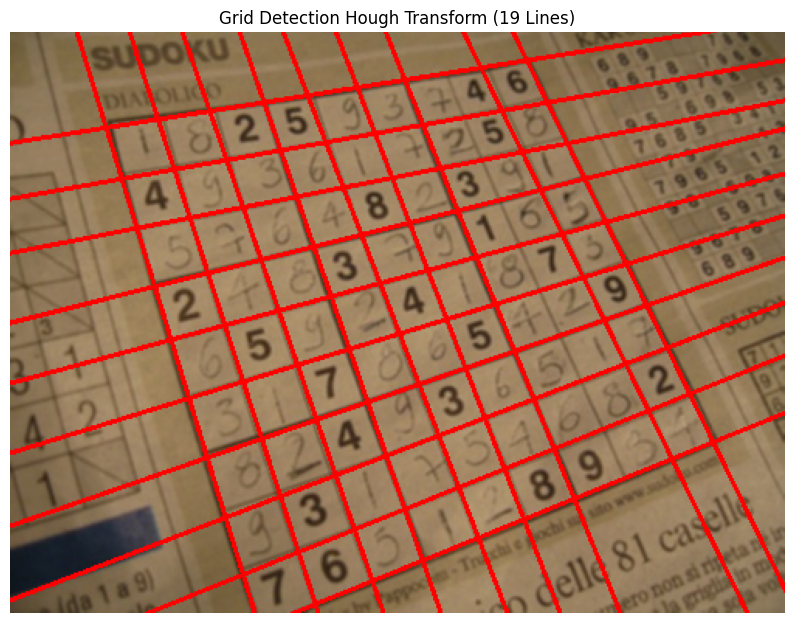

In [12]:
img_bgr = cv.imread('/content/drive/MyDrive/PCVK/Images/sudoku.jpg')
sudoku_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

blurred = cv.GaussianBlur(gray, (5, 5), 0)

# Canny Edge Detection
edges = cv.Canny(blurred, 50, 150, apertureSize=3)

# Dilation & erosion
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

# HoughLines
lines = cv.HoughLines(eroded, rho=1, theta=np.pi/180, threshold=190)

# Tahap 5: Menggabungkan garis yang mirip (Similar Lines Filtering)
def filter_similar_lines(lines, rho_thresh=25, theta_thresh=np.pi/18):
    if lines is None:
        return []
    filtered = []
    for line in lines:
        rho, theta = line[0]
        duplicate = False
        for f_rho, f_theta in filtered:
            diff_rho = abs(abs(rho) - abs(f_rho))
            diff_theta = min(abs(theta - f_theta), np.pi - abs(theta - f_theta))
            if diff_rho < rho_thresh and diff_theta < theta_thresh:
                duplicate = True
                break
        if not duplicate:
            filtered.append((rho, theta))
    return filtered

merged_lines = filter_similar_lines(lines)

sudoku_result = sudoku_rgb.copy()
for rho, theta in merged_lines:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv.line(sudoku_result, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(sudoku_result)
plt.title(f'Grid Detection Hough Transform ({len(merged_lines)} Lines)')
plt.axis('off')
plt.show()

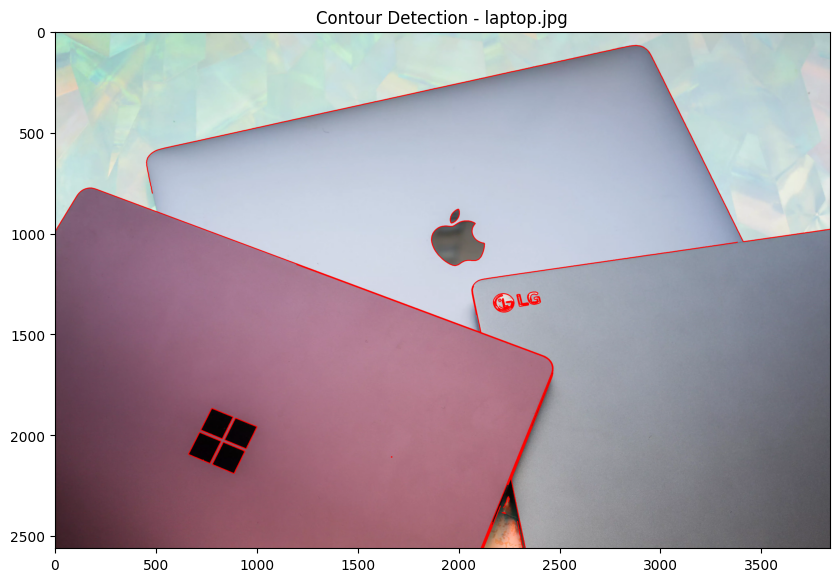

In [13]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar input
img = cv.imread('/content/drive/MyDrive/PCVK/Images/laptop.jpg')

# Konversi ke Grayscale dan RGB
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Tahapan Contour Detection sesuai Modul:
# a. Ubah citra input menjadi citra biner menggunakan thresholding atau Canny edge detection
# Menggunakan Canny edge detection untuk menghasilkan citra biner tepi objek
blurred = cv.GaussianBlur(gray, (5, 5), 0)
thresh = cv.Canny(blurred, 50, 150)

# b. Menemukan kontur menggunakan fungsi findContours()
contours, hierarchy = cv.findContours(
    thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE
)

# c. Menggambarkan kontur pada citra input menggunakan fungsi drawContours()
# Menggambar semua kontur yang ditemukan dengan garis berwarna merah (ketebalan 3)
img_contours = img_rgb.copy()
cv.drawContours(img_contours, contours, -1, (255, 0, 0), 3)

# 3. Tampilkan hasil visualisasi Contour Detection
plt.figure(figsize=(10, 10))
plt.imshow(img_contours)
plt.title('Contour Detection - laptop.jpg')
plt.axis('on')
plt.show()

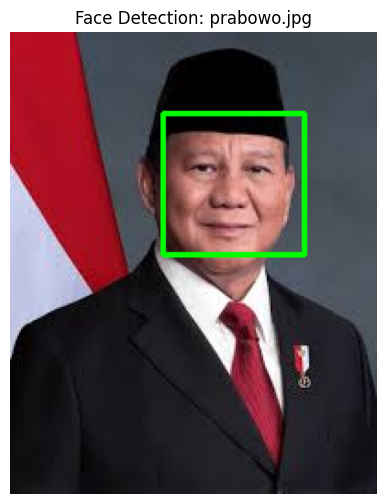

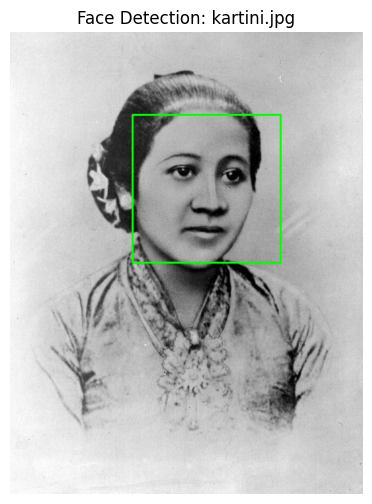

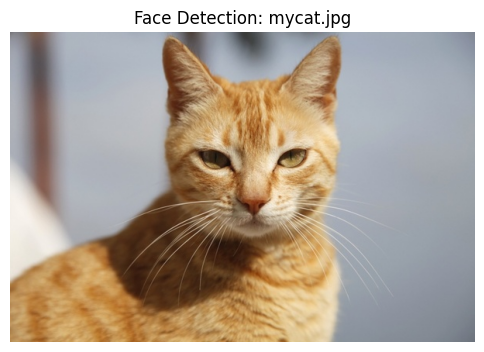

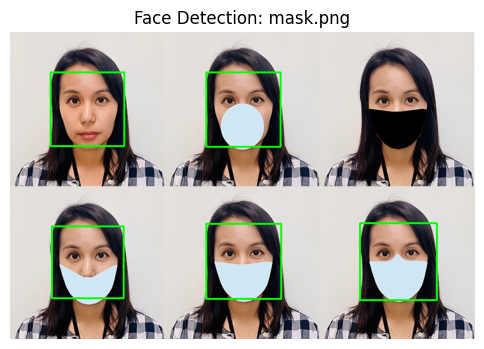

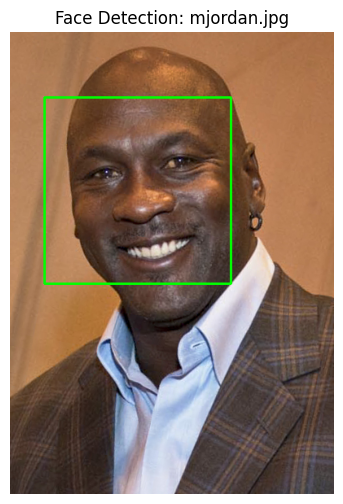

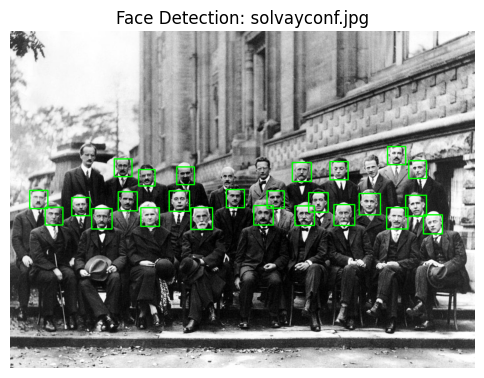

In [15]:
import cv2 as cv
import matplotlib.pyplot as plt
import os

xml_path = cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
face_cascade = cv.CascadeClassifier(xml_path)

def detect_and_draw_face(image_path, scale_factor=1.1, min_neighbors=5):
    img = cv.imread(image_path)
    if img is None:
        print(f"Peringatan: Citra tidak ditemukan di {image_path}")
        return None

    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=scale_factor,
        minNeighbors=min_neighbors,
        minSize=(30, 30)
    )

    # bounding box
    for (x, y, w, h) in faces:
        cv.rectangle(img_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)

    return img_rgb

sample_files = ['prabowo.jpg', 'kartini.jpg', 'mycat.jpg', 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']

for sf in sample_files:
    full_path = f'/content/drive/MyDrive/PCVK/Images/facedet/{sf}'


    if os.path.exists(full_path):
        res_face = detect_and_draw_face(full_path)
        if res_face is not None:
            plt.figure(figsize=(6, 6))
            plt.imshow(res_face)
            plt.title(f'Face Detection: {sf}')
            plt.axis('off')
            plt.show()
    else:
        print(f"File {sf} tidak ditemukan pada path yang ditentukan.")

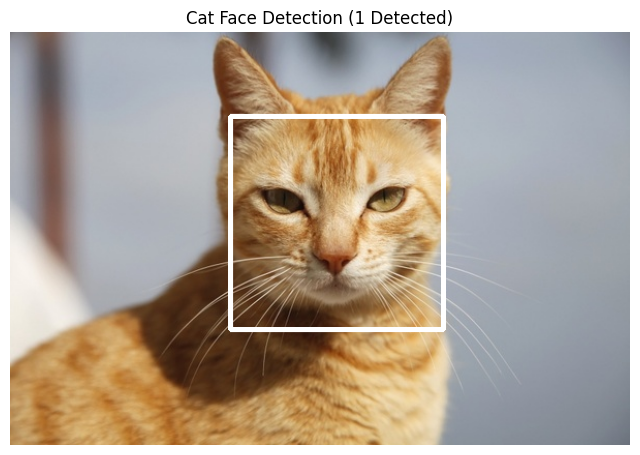

In [19]:
cat_path = '/content/drive/MyDrive/PCVK/Images/facedet/mycat.jpg'
cat_img_bgr = cv.imread(cat_path)

cat_img = cv.cvtColor(cat_img_bgr, cv.COLOR_BGR2RGB)
cat_gray = cv.cvtColor(cat_img, cv.COLOR_BGR2GRAY)

xml_cat_path = cv.data.haarcascades + 'haarcascade_frontalcatface.xml'
cat_cascade = cv.CascadeClassifier(xml_cat_path)

cat_faces = cat_cascade.detectMultiScale(
    cat_gray,
    scaleFactor=1.05,
    minNeighbors=4,
    minSize=(60, 60)
)

cat_result = cat_img.copy()
for (x, y, w, h) in cat_faces:
    cv.rectangle(cat_result, (x, y), (x + w, y + h), (255, 255, 255), 3)

plt.figure(figsize=(8, 6))
plt.imshow(cat_result)
plt.title(f'Cat Face Detection ({len(cat_faces)} Detected)')
plt.axis('off')
plt.show()

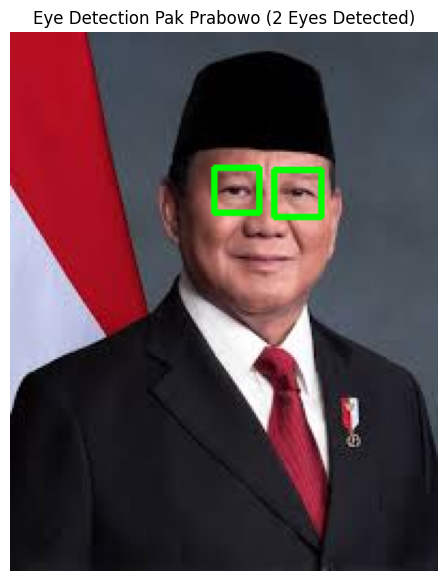

In [21]:
img_path = '/content/drive/MyDrive/PCVK/Images/facedet/prabowo.jpg'

prabowo_bgr = cv.imread(img_path)
prabowo_rgb = cv.cvtColor(prabowo_bgr, cv.COLOR_BGR2RGB)
prabowo_gray = cv.cvtColor(prabowo_bgr, cv.COLOR_BGR2GRAY)

face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
)
eye_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_eye.xml')
faces = face_cascade.detectMultiScale(
    prabowo_gray, scaleFactor=1.05, minNeighbors=5
)

output_img = prabowo_rgb.copy()

for x, y, w, h in faces:
  eye_roi_y_start = int(y + (h * 0.15))
  eye_roi_y_end = int(y + (h * 0.60))
  roi_gray_eye = prabowo_gray[eye_roi_y_start:eye_roi_y_end, x : x + w]

  eyes = eye_cascade.detectMultiScale(
      roi_gray_eye,
      scaleFactor=1.05,
      minNeighbors=3,
      minSize=(10, 10),
      maxSize=(35, 35),
  )

  for ex, ey, ew, eh in eyes:
    abs_x = x + ex
    abs_y = eye_roi_y_start + ey
    cv.rectangle(
        output_img, (abs_x, abs_y), (abs_x + ew, abs_y + eh), (0, 255, 0), 2
    )

plt.figure(figsize=(7, 7))
plt.imshow(output_img)
plt.title(f'Eye Detection Pak Prabowo ({len(eyes)} Eyes Detected)')
plt.axis('off')
plt.show()

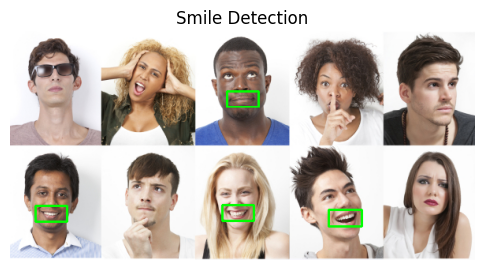

In [28]:
smile_cascade = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/Copy of haarcascade_smile.xml')
jordan_rgb = cv.cvtColor(cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/people.jpg'), cv.COLOR_BGR2RGB)
jordan_gray = cv.cvtColor(jordan_rgb, cv.COLOR_RGB2GRAY)

faces = face_cascade.detectMultiScale(jordan_gray, 1.1, 5)
for (x, y, w, h) in faces:

    roi_gray = jordan_gray[y:y+h, x:x+w]
    roi_color = jordan_rgb[y:y+h, x:x+w]
    smiles = smile_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=10, minSize=(15, 15))
    for (sx, sy, sw, sh) in smiles:
        cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (0, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(jordan_rgb)
plt.title('Smile Detection')
plt.axis('off')
plt.show()

In [29]:
# import dependencies
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import cv2
import numpy as np
import PIL
import io
import html
import time

In [31]:
# function to convert the JavaScript object into an OpenCV image
def js_to_image(js_reply):
  """
  Params:
          js_reply: JavaScript object containing image from webcam
  Returns:
          img: OpenCV BGR image
  """
  # decode base64 image
  image_bytes = b64decode(js_reply.split(',')[1])
  # convert bytes to numpy array
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  # decode numpy array into OpenCV BGR image
  img = cv2.imdecode(jpg_as_np, flags=1)

  return img

# function to convert OpenCV Rectangle bounding box image into base64 byte string to be overlayed on video stream
def bbox_to_bytes(bbox_array):
  """
  Params:
          bbox_array: Numpy array (pixels) containing rectangle to overlay on video stream.
  Returns:
        bytes: Base64 image byte string
  """
  # convert array into PIL image
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
  iobuf = io.BytesIO()
  # format bbox into png for return
  bbox_PIL.save(iobuf, format='png')
  # format return string
  bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))

  return bbox_bytes

In [32]:
# initialize the Haar Cascade face detection model
face_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'))

In [33]:
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)

  # get photo data
  data = eval_js('takePhoto({})'.format(quality))
  # get OpenCV format image
  img = js_to_image(data)
  # grayscale img
  gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
  print(gray.shape)
  # get face bounding box coordinates using Haar Cascade
  faces = face_cascade.detectMultiScale(gray)
  # draw face bounding box on image
  for (x,y,w,h) in faces:
      img = cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)
  # save image
  cv2.imwrite(filename, img)

  return filename

<IPython.core.display.Javascript object>

(480, 640)
Saved to photo.jpg


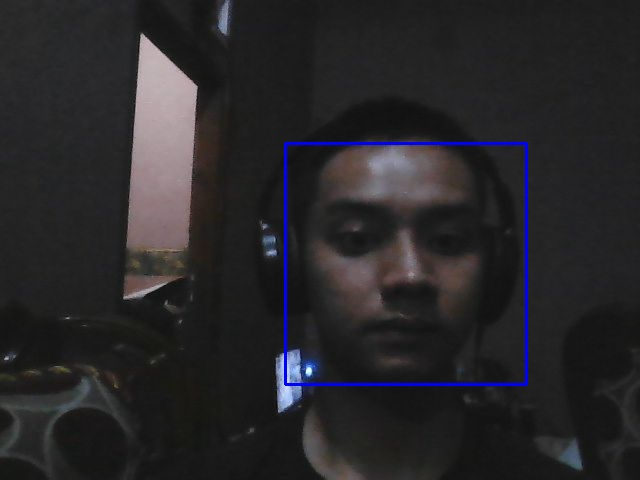

In [35]:
try:
  filename = take_photo('photo.jpg')
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

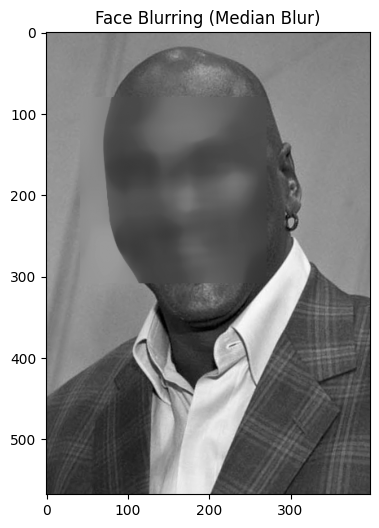

In [37]:
import cv2 as cv
import matplotlib.pyplot as plt

# 1. Load Cascade Classifier untuk wajah
face_cascade = cv.CascadeClassifier(
    '/content/drive/MyDrive/PCVK/Images/haarcascades/Copy of haarcascade_frontalface_alt.xml'
)

# 2. Baca gambar Michael Jordan (mjordan.jpg) dalam mode Grayscale
img_path = '/content/drive/MyDrive/PCVK/Images/facedet/mjordan.jpg'
img_gray = cv.imread(img_path, 0)

assert img_gray is not None, 'File mjordan.jpg tidak ditemukan. Periksa path Anda.'

# 3. Deteksi wajah pada gambar
faces = face_cascade.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

# 4. Lakukan blurring menggunakan cv.medianBlur pada area wajah (ROI)
for x, y, w, h in faces:
  # Ambil bagian Region of Interest (ROI) wajah
  face_roi = img_gray[y : y + h, x : x + w]

  # Terapkan medianBlur (pastikan nilai kernel ganjil, misal 35 atau 45)
  blurred_face = cv.medianBlur(face_roi, 45)

  # Kembalikan area wajah yang sudah diblur ke gambar utama
  img_gray[y : y + h, x : x + w] = blurred_face

# 5. Tampilkan hasil akhir
plt.figure(figsize=(6, 6))
plt.imshow(img_gray, cmap='gray')
plt.title('Face Blurring (Median Blur)')
plt.axis('on')
plt.show()

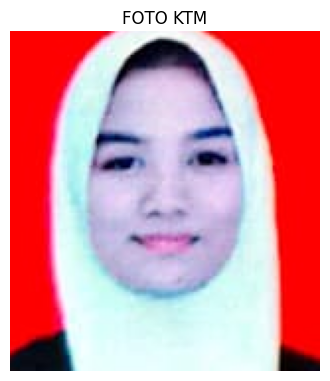

In [40]:
ktm_img = cv.cvtColor(cv.imread('/content/drive/MyDrive/PCVK/Images/KTM Baru.jpg'), cv.COLOR_BGR2RGB)
ktm_gray = cv.cvtColor(ktm_img, cv.COLOR_RGB2GRAY)

faces = face_cascade.detectMultiScale(ktm_gray, scaleFactor=1.05, minNeighbors=6)

for (x, y, w, h) in faces:
    # Padding
    pad = 20
    y1, y2 = max(0, y - pad), min(ktm_img.shape[0], y + h + pad + 15)
    x1, x2 = max(0, x - pad), min(ktm_img.shape[1], x + w + pad)
    foto_ktm = ktm_img[y1:y2, x1:x2]

    plt.figure(figsize=(4, 5))
    plt.imshow(foto_ktm)
    plt.title('FOTO KTM')
    plt.axis('off')
    plt.show()

In [60]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/drive/MyDrive/PCVK/Images/data training"
width, height = 100, 100
training_data = []

# Mengambil semua file gambar di dalam DATADIR
files = sorted(os.listdir(DATADIR))

# Tentukan daftar kelas unik jika diperlukan, atau buat daftar berdasarkan nama file
# Contoh jika nama file diawali dengan label kelas (misal: '0.png' -> kelas '0')
for img in tqdm(files, desc="Processing images"):
    try:
        # Pastikan hanya memproses file gambar (misal berformat .png atau .jpg)
        if not img.lower().endswith(('.png', '.jpg', '.jpeg')):
            continue

        img_path = os.path.join(DATADIR, img)

        # Ekstrak label dari nama file (misal '0.png' -> kelasnya adalah '0')
        class_name = os.path.splitext(img)[0] # Mengambil '0' dari '0.png'

        # Baca gambar dalam bentuk Grayscale
        img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img_array is None:
            continue

        new_array = cv2.resize(img_array, (width, height))
        training_data.append([new_array, class_name])
    except Exception as e:
        pass

random.shuffle(training_data)

X, Y = [], []
# Kumpulkan daftar kelas unik untuk pemetaan indeks
dirs = sorted(list(set([item[1] for item in training_data])))

for feature, class_name in training_data:
    class_number = dirs.index(class_name)
    X.append(feature)
    Y.append(class_number)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

# Simpan dataset ke format pickle
pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("Data sample:", len(training_data))
print("Class:", len(dirs), dirs)

Processing images: 100%|██████████| 10/10 [00:00<00:00, 123.39it/s]

Data sample: 10
Class: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [61]:
import os
os.environ['XLA_FLAGS'] = '--xla_gpu_enable_triton_gemm=false'

import pickle
import numpy as np
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

X = X / 255.0
Y = to_categorical(Y)
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)

# Compile dengan menonaktifkan JIT Compilation (jit_compile=False)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=False  # Mencegah crash compiler Triton GEMM pada GPU
)

batch_sz = min(16, max(2, int(len(X) * 0.8 // 2)))

riwayat = model.fit(
    X, Y,
    epochs=20,
    batch_size=batch_sz,
    verbose=1,
    validation_split=0.2
)

# Simpan model terlatih
model.save('anpr.keras')

print("Akurasi Training :", riwayat.history['accuracy'][-1])
print("Akurasi Validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 488ms/step - accuracy: 0.1250 - loss: 2.3676 - val_accuracy: 0.0000e+00 - val_loss: 2.4360
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.2500 - loss: 2.2777 - val_accuracy: 0.0000e+00 - val_loss: 2.5700
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 356ms/step - accuracy: 0.2500 - loss: 2.2214 - val_accuracy: 0.0000e+00 - val_loss: 2.7490
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 341ms/step - accuracy: 0.2500 - loss: 2.1802 - val_accuracy: 0.0000e+00 - val_loss: 2.9020
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 340ms/step - accuracy: 0.3750 - loss: 2.1348 - val_accuracy: 0.0000e+00 - val_loss: 3.0575
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 325ms/step - accuracy: 0.3750 - loss: 2.1028 - val_accuracy: 0.0000e+00 - val_loss: 3.2181
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 325ms/step - accuracy: 0.3750 - loss: 2.0573 - val_accuracy: 0.0000e+00 - val_loss: 3.3675
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 336ms/step - accuracy: 0.6250 - loss: 2.0052 - val_

In [65]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "/content/drive/MyDrive/PCVK/Images/data training"
width, height = 100, 100

# Muat model dan label kelas yang sudah disimpan
model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

print("--- Memulai Repetisi Prediksi ---")

# Melakukan repetisi/loop untuk setiap file gambar di dalam folder
for img_name in sorted(os.listdir(data_dir_testing)):
    # Lewati jika bukan file gambar
    if not img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        continue

    img_path = os.path.join(data_dir_testing, img_name)

    # Baca gambar dalam format grayscale dan lakukan preprocessing
    img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img_array is None:
        continue

    new_array = cv2.resize(img_array, (width, height))
    new_array = new_array.reshape(-1, width, height, 1) / 255.0

    # Prediksi menggunakan model
    prediction = model.predict(new_array, verbose=0)
    predicted_class = dirs[np.argmax(prediction[0])]

    # Menampilkan hasil tebakan untuk setiap gambar
    print(f"File: {img_name} -> Hasil Tebakan: {predicted_class}")

--- Memulai Repetisi Prediksi ---
File: 0.png -> Hasil Tebakan: 0
File: 1.png -> Hasil Tebakan: 1
File: 2.png -> Hasil Tebakan: 2
File: 3.png -> Hasil Tebakan: 8
File: 4.png -> Hasil Tebakan: 4
File: 5.png -> Hasil Tebakan: 5
File: 6.png -> Hasil Tebakan: 6
File: 7.png -> Hasil Tebakan: 7
File: 8.png -> Hasil Tebakan: 8
File: 9.png -> Hasil Tebakan: 8
